# Lesson 8 — Assemble ACT from its parts

**Your result:** an Action Chunking Transformer built from your functions. It reproduces the installed LeRobot ACT *exactly* when it holds the same weights, and it trains with the loss callback from the training unit.

Five short exercises and a larger experiment. These are estimates, not measurements.

**Sources.** [ACT paper](https://arxiv.org/abs/2304.13705) (action chunks, the CVAE posterior encoder, the Transformer encoder-decoder with learned action queries) and the code in the pinned `lerobot/policies/act/modeling_act.py` (revision `e0d50211ef236143ae867228662b7dfaba554f02`), read as `ACT.forward`. The blocks come from [Attention Is All You Need](https://arxiv.org/abs/1706.03762). **The raw model returns `(actions, (mu, logvar))` and does not compute a loss.** The installed `ACTPolicy.forward` computes its own loss inside; this unit bypasses it on purpose and uses the loss callback from the training unit.

**Supplied here:** the CNN backbone (a ResNet-18 that turns each camera image into a feature map), the Transformer encoder and decoder blocks (package versions of your Lesson 6 and Lesson 7 answers), the data reader, and the weight converter. **You write** the five functions that make ACT *ACT*: 2D camera positions, the posterior encoder, the latent choice (including zero-latent inference), the encoder tokens, and the action decoder.

Full answers are in [the reference notebook](08-act-assembly-reference.ipynb).

# Before you code

This course assumes strong Python skills and basic machine-learning knowledge. We explain PyTorch when it first appears. Read each shape, unit, mask, and parameter definition before you run the check. The reference copy gives a complete solution; the learner copy leaves the implementation for you.

The complete ACT path has a training-only posterior encoder, a latent selection step, an observation encoder, and an action decoder. During training, the posterior reads state and action tokens and returns the mean $\mu$ and log variance $\log\sigma^2$ of the latent $z$. During inference, ACT uses a zero latent. Camera frames become a grid of visual features; position codes identify each grid cell. State and latent tokens join those visual tokens in encoder memory. Learned action queries then read that memory and the action head maps each query to controller values.

The exercises use these size symbols:
* $B$ - batch size.
* $T$ - chunk horizon: predicted action steps.
* $A$ - action width ($A=7$).
* $S$ - state width ($S=8$).
* $L$ - latent width.
* $D$ - model (token) width.
* $C$, $h$, $w$ - channels, height, and width of one camera feature map.
* $N$ - number of encoder tokens.

For $B=2$, $T=20$, $A=7$, and $D=256$, the final action tensor must have shape $(B,T,A)=(2,20,7)$. Shapes at each boundary help locate errors before any simulator run. A parity check loads the same weights into the reference and learner models and compares predictions on identical inputs. Parity checks implementation behavior only; it does not prove that a checkpoint performs the task well. The exercise uses real LeRobot module structure with deterministic synthetic inputs first, then prepared local data when available.


In [31]:
import os
import sys
from collections.abc import Mapping, Sequence

# Supplied: workspace, offline caches, imports
from pathlib import Path

from vla_lab.teaching.blocks import (
    ACTDecoderParts,
    ACTEncoderParts,
    ACTLatentParts,
    ACTPosteriorParts,
)
from vla_lab.teaching.records import AssemblyArm, TrialConfig, TrialResult


def find_root() -> Path:
    for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        if (path / "manifests" / "act_references.yaml").is_file():
            return path
    raise FileNotFoundError("Start Jupyter inside the repository tree.")


WORKSPACE = find_root()
if str(WORKSPACE / "src") not in sys.path:
    sys.path.insert(0, str(WORKSPACE / "src"))

# Set cache paths and offline mode before any data or model library is imported.
os.environ["HF_HUB_CACHE"] = str(WORKSPACE / ".local-data/hf/hub")
os.environ["HF_DATASETS_CACHE"] = str(WORKSPACE / ".local-data/hf/datasets")
os.environ["HF_HUB_OFFLINE"] = "1"
os.environ["HF_DATASETS_OFFLINE"] = "1"
os.environ.setdefault("TORCH_HOME", str(WORKSPACE / ".local-data/torch"))
CONFIGS, DATA = WORKSPACE / "configs", WORKSPACE / ".local-data"
import copy
import time
from functools import partial

import matplotlib.pyplot as plt
import torch
import yaml
from lerobot.configs import FeatureType, PolicyFeature
from lerobot.policies.act.configuration_act import ACTConfig
from lerobot.policies.act.modeling_act import ACT, ACTSinusoidalPositionEmbedding2d
from torch import nn

import vla_lab.teaching.act_model as ref  # package reference: used by checks only
from vla_lab.teaching.act_model import (
    ACTHooks,
    ACTModel,
    ACTSettings,
    act_from_lerobot,
    convert_lerobot_act_state_dict,
    load_act_samples,
    load_lerobot_act,
    make_act_backbone,
    verify_act_parity,
)
from vla_lab.teaching.training import act_loss_fn, masked_action_l1, train_loop

torch.manual_seed(0)
print("PyTorch:", torch.__version__)
print("Workspace:", WORKSPACE)

PyTorch: 2.11.0+cu128
Workspace: /home/michal/code/vlas_tutorial


In [32]:
# Supplied: a helper that the checks use
def close(actual: torch.Tensor, expected: torch.Tensor, message: str, atol: float = 1e-5) -> None:
    """Compare two tensors and say what failed."""
    assert actual.shape == expected.shape, (
        f"{message}: shape {tuple(actual.shape)}, expected {tuple(expected.shape)}"
    )
    worst = (actual.detach() - expected.detach()).abs().max().item()
    assert worst <= atol, f"{message}: largest difference {worst:.2e} is above {atol:.0e}"

## The parts of ACT

```
training only:   [cls, state, action_1 … action_T] ─ posterior encoder ─▶ (mu, logvar) ─▶ sample z
inference:                                                              z = 0
encoder tokens:  [ z, state, camera-1 cells…, camera-2 cells… ]  (+ positions) ─ encoder ─▶ memory
decoder:         T zero queries (+ learned query positions) ─ cross-attend to memory ─▶ T actions
```

- A **camera** goes through the CNN backbone. Its feature map `(C, h, w)` becomes `h*w` tokens of width `D`, each with a fixed 2D sinusoidal position.
- The **posterior encoder** exists only to *train* the latent `z` (a conditional VAE). It sees the future actions, so it can encode "which style of demonstration this was". Padded actions are masked.
- **At inference there are no future actions.** The latent is set to zero, the mean of the prior.
- The **decoder** has no input except learned query positions. Each of the `T` queries asks the memory for one future action.

## Three kinds of weights — keep them apart

| Name | What it is | Where it comes from |
|---|---|---|
| **Reference weights in the learner** | LeRobot ACT weights copied into *your* module by the converter | `load_lerobot_act`; proves your code computes the same function |
| **Learner trained weights** | weights produced by *your* updates in this notebook | the experiment below |
| **Prepared policy results** | numbers saved from the LeRobot policy (e.g. simulator successes) | `manifests/act_references.yaml`; says nothing about your module |

In [33]:
# Supplied: the CNN backbone and a first look
backbone, channels = make_act_backbone("resnet18")
frame = torch.rand(1, 3, 256, 256)
print(
    "feature map for one 256x256 camera:",
    tuple(backbone(frame)["feature_map"].shape),
    "(channels, rows, columns) after the batch axis",
)

feature map for one 256x256 camera: (1, 512, 8, 8) (channels, rows, columns) after the batch axis


In [34]:
# Supplied: a small real LeRobot ACT, its learner twin, and a batch for algorithm checks
IMAGES = ("observation.images.image", "observation.images.image2")


def small_lerobot_act(seed: int = 11) -> ACT:
    """A small *real* pinned ACT module with random weights (64x64 images, 20-step chunk)."""
    torch.manual_seed(seed)
    config = ACTConfig(
        input_features={
            IMAGES[0]: PolicyFeature(FeatureType.VISUAL, (3, 64, 64)),
            IMAGES[1]: PolicyFeature(FeatureType.VISUAL, (3, 64, 64)),
            "observation.state": PolicyFeature(FeatureType.STATE, (8,)),
        },
        output_features={"action": PolicyFeature(FeatureType.ACTION, (7,))},
        chunk_size=20,
        n_action_steps=20,
        dim_model=32,
        n_heads=4,
        dim_feedforward=64,
        n_encoder_layers=2,
        n_decoder_layers=1,
        n_vae_encoder_layers=2,
        latent_dim=6,
        dropout=0.0,
        pretrained_backbone_weights=None,
        push_to_hub=False,
        device="cpu",
    )
    model = ACT(config)
    for parameter in model.parameters():  # distinct vectors make wrong wiring visible
        if parameter.dim() == 1:
            nn.init.normal_(parameter, std=0.1)
    return model


def algorithm_check_batch(
    batch: int = 3, chunk: int = 20, seed: int = 0
) -> dict[str, torch.Tensor]:
    """Random numbers in the right shapes. Clearly labelled: an algorithm check, not data."""
    g = torch.Generator().manual_seed(seed)
    pad = torch.zeros(batch, chunk, dtype=torch.bool)
    pad[1, 14:] = True
    pad[2, 3:] = True
    return {
        "observation.state": torch.randn(batch, 8, generator=g),
        IMAGES[0]: torch.rand(batch, 3, 64, 64, generator=g),
        IMAGES[1]: torch.rand(batch, 3, 64, 64, generator=g),
        "action": torch.randn(batch, chunk, 7, generator=g),
        "action_is_pad": pad,
    }


REFERENCE = small_lerobot_act()  # the installed LeRobot ACT (reference weights)
LEARNER = act_from_lerobot(REFERENCE)  # the learner module holding *reference weights*
CHECK_BATCH = algorithm_check_batch()
print("learner parameters:", sum(p.numel() for p in LEARNER.parameters()))

learner parameters: 11232819


## Exercise 8.1 — 2D positions for camera features

**Purpose.** Camera tokens come from a grid. The encoder needs to know each token's row and column; this is a fixed sinusoidal code, half for the row and half for the column.

**Contract (shapes, units, masks).**

- `camera_position_embedding_2d(height, width, dim)` returns a `float32` tensor `(1, dim, height, width)`; `dim` is even.
- Let `d = dim // 2`. Channels `0 … d-1` encode the **row**, channels `d … dim-1` encode the **column**.
- Row index $r$ runs $1 \dots$ `height` (not from 0). The column index $c$ runs $1 \dots$ `width`. Each is scaled to $(0, 2\pi]$, and channel $j$ of a half gets one sine or cosine of it:

$$\tilde{r}=\frac{r}{\text{height}+10^{-6}}\cdot2\pi, \qquad \theta_j=\frac{\tilde{r}}{10000^{\,2\lfloor j/2\rfloor/d}}, \qquad PE_j=\begin{cases}\sin\theta_j & j \text{ even}\\ \cos\theta_j & j \text{ odd}\end{cases}$$

  Where:
  * $r$ - row index; $\tilde{r}$ - scaled row index.
  * $d$ - `dim // 2`, the channels per half.
  * $j$ - channel index inside the half, $0 \le j < d$; sines and cosines are interleaved.
  * $\theta_j$ - the angle of channel $j$.

  The column half uses the same formulas with $c$ and `width` in place of $r$ and `height`.

**Method and source.** 2D sinusoidal positions as in DETR; ACT uses them for its image tokens ([ACT paper](https://arxiv.org/abs/2304.13705)). The 1D version is Exercise 6.4 ([Vaswani et al. 2017](https://arxiv.org/abs/1706.03762), section 3.5). The pinned class is `ACTSinusoidalPositionEmbedding2d`.

**Pointers.** Make a row code of shape `(height, d)` and a column code of shape `(width, d)` first. Then broadcast them to `(height, width, d)` each, concatenate the row half first, and move channels to the front.

<details><summary>Detailed hint</summary>

```python
per_axis = dim // 2
rows = torch.arange(1, height + 1, dtype=torch.float32)
columns = torch.arange(1, width + 1, dtype=torch.float32)
rows = rows / (rows[-1] + 1e-6) * 2 * math.pi        # same for columns
inverse = 10000 ** (2 * (torch.arange(per_axis) // 2) / per_axis)

def encode(positions):
    angles = positions[:, None] / inverse
    return torch.stack((angles[:, 0::2].sin(), angles[:, 1::2].cos()), dim=-1).flatten(1)

row_code = encode(rows)[:, None, :].expand(height, width, per_axis)
column_code = encode(columns)[None, :, :].expand(height, width, per_axis)
return torch.cat((row_code, column_code), dim=-1).permute(2, 0, 1).unsqueeze(0)
```
`torch.stack((sines, cosines), dim=-1).flatten(1)` interleaves the two.

</details>

More behaviour checks for this exercise: `check_camera_position_embedding_2d` in [lesson08_checks.py](lesson08_checks.py).

In [93]:
# Implement: Exercise 8.1
def camera_position_embedding_2d(height: int, width: int, dim: int) -> torch.Tensor:
    # Return (1, dim, height, width): row code in the first half of channels, column code in the second.
    if dim % 2 != 0:
        raise ValueError("dim not divisible by 2")
    d = dim // 2
    ds = torch.arange(d)[None, :]
    r = torch.arange(1, height + 1)[:, None] * 2 * torch.pi / (height + 1e-6)
    c = torch.arange(1, width + 1)[:, None] * 2 * torch.pi / (width + 1e-6)

    angles_rows = r / torch.pow(10_000, 2 * (ds // 2) / d)
    angles_cols = c / torch.pow(10_000, 2 * (ds // 2) / d)

    pos_rows = torch.zeros_like(angles_rows)
    pos_rows[:, 0::2] = angles_rows[:, 0::2].sin()
    pos_rows[:, 1::2] = angles_rows[:, 1::2].cos()
    pos_cols = torch.zeros_like(angles_cols)
    pos_cols[:, 0::2] = angles_cols[:, 0::2].sin()
    pos_cols[:, 1::2] = angles_cols[:, 1::2].cos()

    pos_rows = pos_rows[:, None, :].expand(height, width, d)
    pos_cols = pos_cols[None, :, :].expand(height, width, d)

    return torch.cat((pos_rows, pos_cols), dim=-1).permute(2, 0, 1).unsqueeze(0)


# Check: Exercise 8.1
for height, width, dim in ((2, 2, 32), (3, 5, 32), (8, 8, 64)):
    expected = ACTSinusoidalPositionEmbedding2d(dim // 2)(torch.zeros(1, 4, height, width))
    mine = camera_position_embedding_2d(height, width, dim)
    assert mine.shape == (1, dim, height, width), (
        f"Expected (1, {dim}, {height}, {width}), got {tuple(mine.shape)}."
    )
    close(
        mine,
        expected,
        f"map for {height}x{width}, dim {dim} differs from ACTSinusoidalPositionEmbedding2d",
        atol=1e-6,
    )
m = camera_position_embedding_2d(4, 6, 16)
assert torch.equal(m[0, :8, 1, 0], m[0, :8, 1, 5]), "Row channels must not depend on the column."
assert torch.equal(m[0, 8:, 0, 2], m[0, 8:, 3, 2]), "Column channels must not depend on the row."
print("Exercise 8.1 passed")

# More behaviour checks: lesson08_checks.py, next to this notebook.
from lesson08_checks import check_camera_position_embedding_2d

check_camera_position_embedding_2d(camera_position_embedding_2d)

Exercise 8.1 passed
✓ matches the formula for 1x1, wide, tall and square grids
✓ row and column halves are not swapped


**Use your function.** Show the position code on the feature grid of one real camera image (the encoder sees exactly this grid).

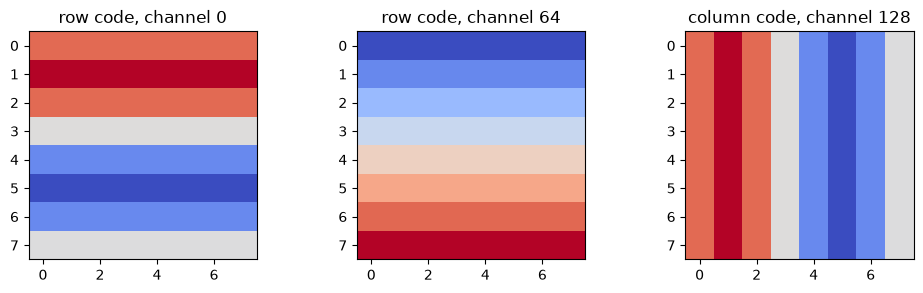

tokens per camera: 64


In [94]:
# Use your function: Exercise 8.1
rows, columns = backbone(frame)["feature_map"].shape[-2:]
codes = camera_position_embedding_2d(rows, columns, 256)
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for axis, channel, title in zip(
    axes,
    (0, 64, 128),
    ("row code, channel 0", "row code, channel 64", "column code, channel 128"),
    strict=True,
):
    axis.imshow(codes[0, channel], cmap="coolwarm")
    axis.set_title(title)
plt.tight_layout()
plt.show()
print("tokens per camera:", rows * columns)

## Exercise 8.2 — The posterior encoder (CLS, state, actions, padding)

**Purpose.** During training the model sees the future actions and encodes them into a latent code. This function turns `(state, actions, padding)` into the mean and log-variance of that latent.

**Contract (shapes, units, masks).**

- `model` has: `vae_cls_embed` (`nn.Embedding` with one row, width `D`), `vae_state_proj` (`Linear(S, D)`), `vae_action_proj` (`Linear(A, D)`), `vae_encoder` (callable `vae_encoder(tokens, pos_embed, key_padding_mask) -> (B, N, D)`), `vae_pos_embed` (fixed table `(1, T + 2, D)`) and `vae_latent_proj` (`Linear(D, 2 * L)`).
- `state (B, S)`, `actions (B, T, A)`, `action_is_pad (B, T)` with `True` = padding.
- Token sequence: `[cls, state, action_1 … action_T]`, shape `(B, T + 2, D)`. The key padding mask is `[False, False, *action_is_pad]`, shape `(B, T + 2)`. Pass `model.vae_pos_embed` as the position.
- Read the encoder output at position 0 (the CLS token), apply `vae_latent_proj`, and split the `2 * L` values: the first `L` are `mu`, the last `L` are `logvar` (the log of the variance, $\log\sigma^2$).
- Return `(mu, logvar)`, each `(B, L)`.

**Method and source.** The posterior `q(z | state, actions)` is a BERT-style Transformer encoder whose CLS output gives a diagonal Gaussian — [ACT paper](https://arxiv.org/abs/2304.13705), section on the CVAE encoder. Pinned code: the `if self.config.use_vae and ACTION in batch and self.training` block of `ACT.forward`.

**Pointers.** Build the three kinds of tokens first and concatenate them on the sequence axis. Build the mask from `action_is_pad` plus two `False` columns on the left. Take only position 0 of the encoder output.

<details><summary>Detailed hint</summary>

```python
batch = state.shape[0]
cls_token = model.vae_cls_embed.weight[None].expand(batch, -1, -1)           # (B, 1, D)
tokens = torch.cat([cls_token, model.vae_state_proj(state)[:, None], model.vae_action_proj(actions)], dim=1)
no_pad = torch.zeros(batch, 2, dtype=torch.bool, device=state.device)
mask = torch.cat([no_pad, action_is_pad.to(torch.bool)], dim=1)
cls_out = model.vae_encoder(tokens, model.vae_pos_embed, mask)[:, 0]
mu, logvar = model.vae_latent_proj(cls_out).chunk(2, dim=-1)
return mu, logvar
```

</details>

More behaviour checks for this exercise: `check_encode_posterior` in [lesson08_checks.py](lesson08_checks.py).

In [95]:
# Implement: Exercise 8.2
def encode_posterior(
    model: ACTPosteriorParts,
    state: torch.Tensor,
    actions: torch.Tensor,
    action_is_pad: torch.Tensor,
) -> tuple[torch.Tensor, torch.Tensor]:
    # Tokens [cls, state, actions]; mask [False, False, *action_is_pad]; read the CLS output; split into mu, logvar.
    batch_size = actions.shape[0]

    cls_enc = model.vae_cls_embed(torch.tensor(0, device=actions.device))[None, None, :].expand(
        (batch_size, -1, -1)
    )
    state_enc = model.vae_state_proj(state)[:, None, :]
    actions_enc = model.vae_action_proj(actions)
    tokens = torch.cat((cls_enc, state_enc, actions_enc), dim=-2)

    key_padding_map = torch.cat(
        (
            torch.zeros((action_is_pad.shape[0], 2), dtype=torch.bool, device=actions.device),
            action_is_pad,
        ),
        dim=-1,
    )

    out = model.vae_encoder(tokens, model.vae_pos_embed, key_padding_map)
    cls_out = out[:, 0]
    latent = model.vae_latent_proj(cls_out)
    L = latent.shape[1] // 2
    mu = latent[:, :L]
    logvar = latent[:, L:]

    return mu, logvar


# Check: Exercise 8.2
# The module passed in is the learner twin of a real pinned ACT, so a correct function reproduces the pinned posterior.
model = copy.deepcopy(LEARNER).train()
batch = CHECK_BATCH
mu, logvar = encode_posterior(
    model, batch["observation.state"], batch["action"], batch["action_is_pad"]
)
assert mu.shape == (3, 6) and logvar.shape == (3, 6), "mu and logvar must be (B, latent_dim)."
reference = copy.deepcopy(REFERENCE).train()
_, (ref_mu, ref_logvar) = reference({**batch, "observation.images": [batch[k] for k in IMAGES]})
close(mu, ref_mu, "mu differs from the pinned ACT posterior")
close(logvar, ref_logvar, "logvar differs from the pinned ACT posterior")
shaken = batch["action"].clone()
shaken[batch["action_is_pad"]] = 60.0
mu2, logvar2 = encode_posterior(model, batch["observation.state"], shaken, batch["action_is_pad"])
close(mu2, mu, "changing padded actions must not change mu", atol=1e-4)
close(logvar2, logvar, "changing padded actions must not change logvar", atol=1e-4)
mu3, _ = encode_posterior(
    model, batch["observation.state"], shaken, torch.zeros_like(batch["action_is_pad"])
)
assert not torch.allclose(mu3, mu, atol=1e-2), (
    "Without the padding mask, the padded values should matter."
)
print("Exercise 8.2 passed")

# More behaviour checks: lesson08_checks.py, next to this notebook.
from lesson08_checks import check_encode_posterior

check_encode_posterior(encode_posterior)

Exercise 8.2 passed
✓ tokens are [cls, state, action_1..T]; mask is [False, False, *action_is_pad]; pos is vae_pos_embed
✓ reads the CLS output (position 0) and splits mu first, logvar second


**Use your function.** Encode real demonstration chunks (with their natural end-of-episode padding) and check that padded values do not leak into the latent.

In [96]:
# Use your function: Exercise 8.2
SMALL_REAL = load_act_samples(
    CONFIGS, DATA, "bowl_plate", "validation", count=8, chunk_size=20, image_size=64
)
learner = copy.deepcopy(LEARNER).eval()
with torch.no_grad():
    mu, logvar = encode_posterior(
        learner, SMALL_REAL["observation.state"], SMALL_REAL["action"], SMALL_REAL["action_is_pad"]
    )
    shaken = torch.where(
        SMALL_REAL["action_is_pad"].unsqueeze(-1),
        torch.full_like(SMALL_REAL["action"], 25.0),
        SMALL_REAL["action"],
    )
    mu_shaken, _ = encode_posterior(
        learner, SMALL_REAL["observation.state"], shaken, SMALL_REAL["action_is_pad"]
    )
print("padded steps per window:", SMALL_REAL["action_is_pad"].sum(1).tolist())
print("largest change of mu when padded actions are replaced:", float((mu - mu_shaken).abs().max()))
print("mu shape:", tuple(mu.shape))

padded steps per window: [0, 0, 8, 0, 9, 0, 0, 19]
largest change of mu when padded actions are replaced: 0.0
mu shape: (8, 6)


## Exercise 8.3 — Choosing the latent: sample in training, zero at inference

**Purpose.** The decoder needs a latent vector. In training it is a sample from the posterior. At inference there are no future actions, so use the prior mean: zero. Getting this branch wrong is a common ACT bug.

**Contract (shapes, units, masks).**

- `model.training` (bool), `model.settings.latent_dim` (`L`), `model.hooks.posterior(model, state, actions, action_is_pad) -> (mu, logvar)`.
- `batch` has `observation.state (B, S)`; in training it also has `action (B, T, A)` and `action_is_pad (B, T)`.
- **Training branch** (`model.training` and `\"action\"` in `batch`): get `(mu, logvar)` from `model.hooks.posterior`, then $z=\mu+e^{\log\sigma^2/2}\odot\varepsilon$, where $\varepsilon$ is `noise`. `noise` defaults to standard normal noise of the shape of `mu`; if given, use it exactly. Use `reparameterize` (supplied, from the training unit) for the sampling step. Return `(z, mu, logvar)`.
- **Otherwise** (evaluation mode, or no actions in the batch): return `(zeros (B, L), None, None)` with the dtype and device of `batch["observation.state"]`. No random numbers.

**Method and source.** Reparameterization trick (Kingma and Welling 2014) and the ACT paper's inference rule: at test time the latent is set to the mean of the prior, zero. Pinned code: the `else` branch that creates `latent_sample = torch.zeros(...)`.

**Pointers.** One `if` with two branches. In the first branch call the hook, then `reparameterize(mu, logvar, noise=noise)`. In the second, only create zeros.

<details><summary>Detailed hint</summary>

```python
state = batch["observation.state"]
if model.training and "action" in batch:
    mu, logvar = model.hooks.posterior(model, state, batch["action"], batch["action_is_pad"])
    return reparameterize(mu, logvar, noise=noise), mu, logvar
zeros = torch.zeros(state.shape[0], model.settings.latent_dim, dtype=state.dtype, device=state.device)
return zeros, None, None
```

</details>

More behaviour checks for this exercise: `check_select_latent` in [lesson08_checks.py](lesson08_checks.py).

In [97]:
from vla_lab.teaching.cvae import reparameterize


# Implement: Exercise 8.3
def select_latent(
    model: ACTLatentParts, batch: Mapping[str, torch.Tensor], noise: torch.Tensor | None = None
) -> tuple[torch.Tensor, torch.Tensor | None, torch.Tensor | None]:
    # Return (latent, mu, logvar): sampled in training, zeros (and None, None) otherwise.
    state = batch["observation.state"]
    if model.training and "action" in batch:
        actions = batch["action"]
        action_is_pad = batch["action_is_pad"]
        mu, logvar = model.hooks.posterior(model, state, actions, action_is_pad)
        z = reparameterize(mu, logvar, noise=noise)
    else:
        mu, logvar = None, None
        z = torch.zeros(
            (state.shape[0], model.settings.latent_dim), dtype=state.dtype, device=state.device
        )

    return z, mu, logvar


# Check: Exercise 8.3
model = copy.deepcopy(LEARNER)
model.hooks = ACTHooks(
    posterior=ref.encode_posterior
)  # the posterior hook is the package answer here
batch = CHECK_BATCH
model.train()
noise = torch.randn(3, 6)
z, mu, logvar = select_latent(model, batch, noise)
ref_mu, ref_logvar = ref.encode_posterior(
    model, batch["observation.state"], batch["action"], batch["action_is_pad"]
)
close(mu, ref_mu, "mu must come from the posterior hook")
close(logvar, ref_logvar, "logvar must come from the posterior hook")
close(z, ref_mu + (ref_logvar / 2).exp() * noise, "z must be mu + exp(logvar / 2) * noise")
z0, _, _ = select_latent(model, batch, torch.zeros(3, 6))
close(z0, ref_mu, "zero noise gives z = mu")
torch.manual_seed(5)
a, _, _ = select_latent(model, batch)
torch.manual_seed(5)
b, _, _ = select_latent(model, batch)
assert torch.equal(a, b) and not torch.allclose(a, ref_mu, atol=1e-3), (
    "Without noise argument, use random noise from the global generator."
)
model.eval()
z, mu, logvar = select_latent(model, batch)
assert mu is None and logvar is None and z.shape == (3, 6) and not z.any(), (
    "Evaluation mode must give a zero latent and no posterior."
)
model.train()
z, mu, logvar = select_latent(model, {"observation.state": batch["observation.state"]})
assert mu is None and not z.any(), "Without actions the latent is zero even in training mode."
print("Exercise 8.3 passed")

# More behaviour checks: lesson08_checks.py, next to this notebook.
from lesson08_checks import check_select_latent

check_select_latent(select_latent)

Exercise 8.3 passed
✓ training: z = mu + exp(logvar / 2) * noise from the hook's outputs
✓ evaluation: zeros (B, L) in the state's dtype, no posterior call, no random numbers


**Use your function.** See both branches on real data: the sampled latent in training mode and the zero latent at inference.

In [98]:
# Use your function: Exercise 8.3
model = copy.deepcopy(LEARNER)
model.hooks = ACTHooks(posterior=ref.encode_posterior, latent=select_latent)
with torch.no_grad():
    model.train()
    z, mu, logvar = select_latent(model, SMALL_REAL)
    print("training latent mean |z|:", float(z.abs().mean()), "| |mu|:", float(mu.abs().mean()))
    model.eval()
    z, mu, logvar = select_latent(model, SMALL_REAL)
    print("inference latent is zero:", not bool(z.any()), "| mu is None:", mu is None)

training latent mean |z|: 0.6973384022712708 | |mu|: 0.058585409075021744
inference latent is zero: True | mu is None: True


## Exercise 8.4 — Encoder tokens: latent, state and camera cells

**Purpose.** Assemble everything the encoder reads into one sequence, with a position for every token.

**Contract (shapes, units, masks).**

- `model` has `latent_proj` (`Linear(L, D)`), `state_proj` (`Linear(S, D)`), `camera_proj` (`Conv2d(C, D, 1)`), `pos_1d` (`nn.Embedding(2, D)`), `settings.dim_model` (`D`), and `hooks.camera_positions(height, width, dim) -> (1, dim, height, width)`.
- Inputs: `latent (B, L)`, `state (B, S)`, `feature_maps`: a list with one `(B, C, h, w)` tensor per camera.
- Return `tokens (B, N, D)` and `pos (1, N, D)` with `N = 2 + sum(h * w)`.
- **Token order:** latent token (`latent_proj(latent)`), state token (`state_proj(state)`), then camera 1 cells row by row, then camera 2, … A feature map becomes tokens by `camera_proj` then flattening `(h, w)` to `h*w` (row-major) with the feature axis last.
- **Positions, same order and device:** the two rows of `model.pos_1d.weight` for the latent and state tokens; then for each camera `model.hooks.camera_positions(h, w, D)` flattened the same way (call the hook once per camera). Convert each camera position tensor to the feature tensor's device and dtype before you append it.

**Method and source.** ACT encoder input: `[latent, state, image feature map pixels]` with learned positions for the first two and sinusoidal 2D positions for the pixels ([ACT paper](https://arxiv.org/abs/2304.13705), appendix; pinned `ACT.forward`).

**Pointers.** Start two lists, `tokens` and `positions`. Each entry has the shape `(B, n, D)` or `(1, n, D)`. Use `flatten(2)` and `transpose(1, 2)` for `(B, D, h, w) → (B, h*w, D)`.

<details><summary>Detailed hint</summary>

```python
tokens = [model.latent_proj(latent)[:, None], model.state_proj(state)[:, None]]    # (B, 1, D) each
positions = [model.pos_1d.weight[None]]                                           # (1, 2, D)
for features in feature_maps:
    height, width = features.shape[-2:]
    tokens.append(model.camera_proj(features).flatten(2).transpose(1, 2))          # (B, h*w, D)
    camera_pos = model.hooks.camera_positions(height, width, model.settings.dim_model)
    positions.append(camera_pos.to(device=features.device, dtype=features.dtype).flatten(2).transpose(1, 2))  # (1, h*w, D)
return torch.cat(tokens, dim=1), torch.cat(positions, dim=1)
```

</details>

More behaviour checks for this exercise: `check_build_encoder_tokens` in [lesson08_checks.py](lesson08_checks.py).

In [99]:
# Implement: Exercise 8.4
def build_encoder_tokens(
    model: ACTEncoderParts,
    latent: torch.Tensor,
    state: torch.Tensor,
    feature_maps: list[torch.Tensor],
) -> tuple[torch.Tensor, torch.Tensor]:
    # Return (tokens (B, N, D), pos (1, N, D)): latent, state, then each camera's cells in row-major order.
    latent_enc = model.latent_proj(latent).unsqueeze(1)
    state_enc = model.state_proj(state).unsqueeze(1)
    cameras_enc = [model.camera_proj(cam).flatten(2).transpose(1, 2) for cam in feature_maps]
    tokens = torch.cat((latent_enc, state_enc, *cameras_enc), dim=-2)

    pos1d = model.pos_1d(torch.arange(2, device=state.device))[None]
    pos2d = [
        model.hooks.camera_positions(cam.shape[-2], cam.shape[-1], model.settings.dim_model)
        .flatten(2)
        .transpose(1, 2)
        .to(dtype=cam.dtype, device=cam.device)
        for cam in feature_maps
    ]
    positions = torch.cat((pos1d, *pos2d), dim=-2)

    return tokens, positions


# Check: Exercise 8.4
model = copy.deepcopy(LEARNER).eval()
batch = CHECK_BATCH
maps = [model.backbone(batch[key])["feature_map"] for key in IMAGES]
latent = torch.randn(3, 6)
seen = []


def counting_positions(height: int, width: int, dim: int) -> torch.Tensor:
    seen.append((height, width, dim))
    return camera_position_embedding_2d(height, width, dim)


model.hooks = ACTHooks(camera_positions=counting_positions)
tokens, pos = build_encoder_tokens(model, latent, batch["observation.state"], maps)
cells = sum(m.shape[-2] * m.shape[-1] for m in maps)
assert tokens.shape == (3, 2 + cells, 32) and pos.shape == (1, 2 + cells, 32), (
    f"Expected tokens (3, {2 + cells}, 32) and pos (1, {2 + cells}, 32)."
)
assert seen == [(maps[0].shape[-2], maps[0].shape[-1], 32)] * 2, (
    f"Call the camera position hook once per camera with (h, w, D); saw {seen}."
)
close(tokens[:, 0], model.latent_proj(latent), "token 0 must be the latent token")
close(tokens[:, 1], model.state_proj(batch["observation.state"]), "token 1 must be the state token")
close(pos[0, :2], model.pos_1d.weight, "positions 0 and 1 come from pos_1d")
projected = model.camera_proj(maps[0])
close(tokens[:, 2], projected[:, :, 0, 0], "first camera token is cell (row 0, column 0)")
close(
    tokens[:, 2 + maps[0].shape[-1]],
    projected[:, :, 1, 0],
    "row-major order: the next row starts after one row of cells",
)
oracle_tokens, oracle_pos = ref.build_encoder_tokens(
    model, latent, batch["observation.state"], maps
)
close(tokens, oracle_tokens, "tokens differ from the reference")
close(pos, oracle_pos, "positions differ from the reference")
print("Exercise 8.4 passed")

# More behaviour checks: lesson08_checks.py, next to this notebook.
from lesson08_checks import check_build_encoder_tokens

check_build_encoder_tokens(build_encoder_tokens)

Exercise 8.4 passed
✓ each camera uses its own size and positions, in order, row by row


**Use your function.** Build the encoder input for real camera frames and push it through the (supplied) Transformer encoder.

In [100]:
# Use your function: Exercise 8.4
model = copy.deepcopy(LEARNER).eval()
model.hooks = ACTHooks(camera_positions=camera_position_embedding_2d)
with torch.no_grad():
    maps = [model.backbone(SMALL_REAL[key])["feature_map"] for key in IMAGES]
    tokens, pos = build_encoder_tokens(
        model, torch.zeros(8, 6), SMALL_REAL["observation.state"], maps
    )
    memory = model.encoder(tokens, pos)
print(
    "token sequence:",
    tuple(tokens.shape),
    "= latent + state +",
    [int(m.shape[-2] * m.shape[-1]) for m in maps],
    "camera cells",
)
print("encoder memory:", tuple(memory.shape))

token sequence: (8, 10, 32) = latent + state + [4, 4] camera cells
encoder memory: (8, 10, 32)


## Exercise 8.5 — Action queries, decoder and head

**Purpose.** Turn the encoder memory into a chunk of actions. The decoder input is zeros: only the learned query positions say which future step each query is.

**Contract (shapes, units, masks).**

- `model` has `settings.chunk_size` (`T`), `settings.dim_model` (`D`), `decoder` (callable `decoder(x, memory, query_pos, memory_pos) -> (B, T, D)`), `query_embed` (`nn.Embedding(T, D)`) and `action_head` (`Linear(D, A)`).
- `encoder_out (B, N, D)`, `pos (1, N, D)` (the positions of the encoder tokens).
- Decoder input `x`: zeros `(B, T, D)` with the dtype and device of `encoder_out`. Query position: `model.query_embed.weight[None]`, shape `(1, T, D)`. Memory position: `pos`.
- Return `action_head(decoder_output)`, shape `(B, T, A)`.

**Method and source.** DETR-style learned object queries, used by ACT as *action queries* ([ACT paper](https://arxiv.org/abs/2304.13705)). Pinned code: the `decoder_in = torch.zeros(...)` lines of `ACT.forward`.

**Pointers.** Make zeros, call the decoder with the three position-related arguments, apply the head.

<details><summary>Detailed hint</summary>

```python
batch = encoder_out.shape[0]
queries = torch.zeros(batch, model.settings.chunk_size, model.settings.dim_model,
                      dtype=encoder_out.dtype, device=encoder_out.device)
out = model.decoder(queries, encoder_out, model.query_embed.weight[None], pos)
return model.action_head(out)
```

</details>

More behaviour checks for this exercise: `check_decode_actions` in [lesson08_checks.py](lesson08_checks.py).

In [101]:
# Implement: Exercise 8.5
def decode_actions(
    model: ACTDecoderParts, encoder_out: torch.Tensor, pos: torch.Tensor
) -> torch.Tensor:
    # Zero queries + learned query positions, cross-attend to the encoder output, then the action head.
    B = encoder_out.shape[0]
    T = model.settings.chunk_size
    D = model.settings.dim_model
    x = torch.zeros((B, T, D), dtype=encoder_out.dtype, device=encoder_out.device)
    query_pos = model.query_embed.weight[None]

    out = model.decoder(x, encoder_out, query_pos, pos)
    chunk = model.action_head(out)

    return chunk


# Check: Exercise 8.5
class RecordingDecoder(nn.Module):
    """Stands in for the decoder module and records its arguments."""

    def forward(
        self,
        x: torch.Tensor,
        memory: torch.Tensor,
        query_pos: torch.Tensor | None = None,
        memory_pos: torch.Tensor | None = None,
        memory_key_padding_mask: torch.Tensor | None = None,
    ) -> torch.Tensor:
        self.args = (x, memory, query_pos, memory_pos)
        return x + 1.0


model = copy.deepcopy(LEARNER).eval()
encoder_out, pos = torch.randn(3, 9, 32), torch.randn(1, 9, 32)
actions = decode_actions(model, encoder_out, pos)
assert actions.shape == (3, 20, 7), "Expected (B, chunk_size, action_dim)."
close(
    actions,
    ref.decode_actions(model, encoder_out, pos),
    "actions differ from the reference decoding",
)
probe = copy.deepcopy(model)
probe.decoder = RecordingDecoder()
out = decode_actions(probe, encoder_out, pos)
x, memory, query_pos, memory_pos = probe.decoder.args
assert x.shape == (3, 20, 32) and not x.any(), "The decoder input must be zeros (B, T, D)."
assert torch.equal(memory, encoder_out) and torch.equal(memory_pos, pos), (
    "Pass the encoder output and its positions."
)
assert torch.equal(query_pos, probe.query_embed.weight[None]), (
    "The query position is the learned query_embed table."
)
close(
    out, probe.action_head(torch.ones(3, 20, 32)), "the head must be applied to the decoder output"
)
print("Exercise 8.5 passed")

# More behaviour checks: lesson08_checks.py, next to this notebook.
from lesson08_checks import check_decode_actions

check_decode_actions(decode_actions)

Exercise 8.5 passed
✓ zero queries (B, T, D) in the memory dtype; learned query positions; head on the output


**Use your function.** Run the five functions together on real data without training. The prediction is from reference weights in a small random LeRobot ACT, so its numbers mean nothing; the shapes and the zero-latent path are the point.

In [102]:
# Use your function: Exercise 8.5
model = copy.deepcopy(LEARNER).eval()
model.hooks = ACTHooks(
    camera_positions=camera_position_embedding_2d,
    posterior=encode_posterior,
    latent=select_latent,
    encoder_tokens=build_encoder_tokens,
    decode=decode_actions,
)
with torch.no_grad():
    actions, (mu, logvar) = model(SMALL_REAL)
print("predicted chunk:", tuple(actions.shape), "| posterior returned:", mu, logvar)

predicted chunk: (8, 20, 7) | posterior returned: None None


## Assemble: your five functions inside the real model

The next cells build an `ACTModel` whose five hooks are **your** functions. The model has the pinned structure (posterior encoder, encoder, decoder, head). We then copy the weights of the small real LeRobot ACT into it. Before that copy, the learner has random weights; after it, it holds *reference weights in the learner* and must give the same numbers as the reference. Only then is it safe to use.

In [103]:
# Supplied: assemble the model from YOUR functions (random weights at first)
YOUR_HOOKS = ACTHooks(
    camera_positions=camera_position_embedding_2d,
    posterior=encode_posterior,
    latent=select_latent,
    encoder_tokens=build_encoder_tokens,
    decode=decode_actions,
)
settings = ACTSettings.from_lerobot(REFERENCE.config)
backbone, channels = make_act_backbone(settings.vision_backbone)
YOURS = ACTModel(settings, backbone, channels, YOUR_HOOKS)
before = verify_act_parity(YOURS, REFERENCE, CHECK_BATCH)
print(
    "random weights, largest difference from reference:",
    {k: round(v, 3) for k, v in before.items()},
)

random weights, largest difference from reference: {'inference_actions': 1.386, 'training_actions': 1.435, 'mu': 0.793, 'logvar': 1.124}


In [104]:
# Supplied: copy the reference weights into your module (explicit converter, strict loading)
converted = convert_lerobot_act_state_dict(REFERENCE.state_dict())
print(
    "tensors after conversion:",
    len(converted),
    "| LeRobot tensors:",
    len(REFERENCE.state_dict()),
    "(each packed attention tensor becomes query, key and value tensors)",
)
print(load_lerobot_act(YOURS, REFERENCE))

tensors after conversion: 210 | LeRobot tensors: 186 (each packed attention tensor becomes query, key and value tensors)
{'tensors': 210, 'parameters': 11232819}


In [105]:
# Check: identical weights and inputs must give identical outputs
after = verify_act_parity(YOURS, REFERENCE, CHECK_BATCH)
print({k: f"{v:.1e}" for k, v in after.items()})
assert after["inference_actions"] < 1e-4, "Zero-latent inference path differs from the pinned ACT."
assert after["training_actions"] < 1e-4 and after["mu"] < 1e-5 and after["logvar"] < 1e-5, (
    "Posterior path differs from the pinned ACT."
)
print("Parity with the pinned ACT: passed")

{'inference_actions': '6.0e-08', 'training_actions': '6.0e-08', 'mu': '3.0e-08', 'logvar': '3.0e-08'}
Parity with the pinned ACT: passed


In [106]:
# Check: your model plus the training unit's loss callback equals the pinned policy loss
from lerobot.policies.act import ACTPolicy

pinned_policy = ACTPolicy(REFERENCE.config)
pinned_policy.model.load_state_dict(REFERENCE.state_dict())
pinned_policy.train()
YOURS.train()
torch.manual_seed(7)
pinned_loss, pinned_parts = pinned_policy(
    dict(CHECK_BATCH)
)  # the pinned loss path, used only for comparison
torch.manual_seed(7)
your_loss, your_parts = act_loss_fn(YOURS, CHECK_BATCH, kl_weight=REFERENCE.config.kl_weight)
print("pinned policy loss:", float(pinned_loss), "| your model + act_loss_fn:", float(your_loss))
assert abs(float(pinned_loss) - float(your_loss)) < 1e-4, (
    "The two loss paths must agree for equal weights."
)

pinned policy loss: 1.5700199604034424 | your model + act_loss_fn: 1.5700197219848633


### Prepared checkpoint: real-size parity before any live use

The same check at real size: the local **prepared** ACT checkpoint `act-bowl-plate-probe-200` (a 200-step LeRobot training run) is copied into your module and compared on real camera frames at 256×256. This reads local files only; no download starts. If the files are missing, the cell says how to install them. Parity must hold before you run your module in the simulator.

In [107]:
from lerobot.policies.act import ACTPolicy

checkpoint = DATA / "runs/act-bowl-plate-probe-200/checkpoint-000200"
if not (checkpoint / "model.safetensors").is_file():
    print(
        "Prepared ACT checkpoint not found. Install the reference bundle with `just references-install` (outside this notebook)."
    )
else:
    config = ACTConfig.from_pretrained(checkpoint, local_files_only=True)
    config.device = "cpu"
    prepared = ACTPolicy.from_pretrained(
        checkpoint, config=config, strict=True, local_files_only=True
    )
    full_size = act_from_lerobot(
        prepared.model, hooks=YOUR_HOOKS
    )  # reference weights in the learner
    real = load_act_samples(
        CONFIGS, DATA, "bowl_plate", "validation", count=4, chunk_size=config.chunk_size
    )
    diffs = verify_act_parity(full_size, prepared.model, real)
    print("largest differences at real size:", {k: f"{v:.1e}" for k, v in diffs.items()})
    assert max(diffs.values()) < 5e-4, (
        "Reference weights in your module must reproduce the pinned model."
    )
    saved = yaml.safe_load((WORKSPACE / "manifests/act_references.yaml").read_text())["tasks"][
        "bowl_plate"
    ]
    print(
        "Prepared policy result (saved by the project, simulator development states; NOT produced here):",
        saved["development_successes"],
        "of",
        saved["development_episodes"],
    )

Loading weights from local directory
largest differences at real size: {'inference_actions': '4.2e-07', 'training_actions': '6.0e-07', 'mu': '4.2e-07', 'logvar': '3.0e-07'}
Prepared policy result (saved by the project, simulator development states; NOT produced here): 19 of 20


## Experiment — which inputs does your ACT need?

**Question.** ACT reads state, two cameras and 2D camera positions. Which of these does a *small, briefly trained* ACT use, measured on held-out real demonstrations at inference (zero latent)?

**Setup (real data).** 256 training windows and 64 validation windows, spread evenly over the frozen `bowl_plate` train and validation episodes; each has both camera images (box-filtered to 32×32 so that CPU training is fast), the 8-value state and 20 actions (standardized with training statistics; windows near the end of an episode have padded actions). The model is a small ACT (width 64, 4 heads, latent 8) with a ResNet-18 backbone and **your five functions**. The loss is the training unit's `act_loss_fn` with `kl_weight` below, run by `train_loop`.

**Fixed for every trial.** The data above; weight seed `0`; batch seed `1`; **150 updates**, batch 8, AdamW with weight decay `1e-4`. These are *learner trained weights*: they start from random numbers, not from the prepared checkpoint.

**Allowed changes (per trial).** `arm`, `lr` (`3e-4` or `1e-3`), `kl_weight` (`0.1` or `10`). `arm` is an `AssemblyArm` member (from `vla_lab.teaching.records`); each one swaps one hook function:
* `AssemblyArm.FULL` - your hooks unchanged.
* `AssemblyArm.NO_CAM_POS` - camera cells get zero positions, so the encoder cannot tell where a cell is.
* `AssemblyArm.ONE_CAMERA` - only the first (agent-view) camera.
* `AssemblyArm.STATE_ONLY` - no camera tokens.
* `AssemblyArm.CAMERAS_ONLY` - the robot state is replaced by zeros.

**Measures.** `val_l1_zero`: masked L1 on validation windows with the zero latent (the inference path). `val_l1_posterior`: the same with the latent set to the posterior mean (an optimistic bound that uses the true future actions). `val_kl`: posterior KL. Also report a *do-nothing baseline*: the L1 of always predicting the training mean action.

**Prediction first.** In the next cell write which arm you expect to be best and which worst, and whether `val_l1_posterior` will be far below `val_l1_zero`.

**Keep failed trials.** Every trial is appended to `TRIALS` as a `TrialResult` dict: `config` holds the trial's `TrialConfig` settings, `status` is `"ok"` or `"failed: <error>"`, and the measures above are extra keys of the same row. A run that is no better than the baseline is a valid result. One hundred fifty updates are too few to get a good policy; this experiment compares *inputs*, not final quality.

In [108]:
# Run this cell to start the larger training experiment.


In [109]:
# Write your prediction in the Markdown cell above before you run the experiment.


In [110]:
# Supplied: trial table helper
import pandas as pd


def show_trials(trials: Sequence[TrialResult], columns: Sequence[str]) -> pd.DataFrame:
    """Print every trial that was run, including failed ones, and return a table."""
    table = pd.DataFrame(
        [{**t["config"], **{c: t.get(c) for c in columns}, "status": t["status"]} for t in trials]
    )
    print(table.to_string(index=False, float_format=lambda v: f"{v:.4g}"))
    return table

In [111]:
# Supplied: data for the experiment (real windows, 32x32 images)
SIZE, CHUNK = 32, 20
TRAIN = load_act_samples(
    CONFIGS, DATA, "bowl_plate", "train", count=256, chunk_size=CHUNK, image_size=SIZE
)
VALID = load_act_samples(
    CONFIGS, DATA, "bowl_plate", "validation", count=64, chunk_size=CHUNK, image_size=SIZE
)
baseline_prediction = TRAIN["action"][~TRAIN["action_is_pad"]].mean(0)
do_nothing = masked_action_l1(
    baseline_prediction.expand_as(VALID["action"]), VALID["action"], VALID["action_is_pad"]
).item()
print(
    "train windows:",
    len(TRAIN["action"]),
    "validation windows:",
    len(VALID["action"]),
    "| image size:",
    SIZE,
)
print("do-nothing baseline (always the mean training action), L1:", round(do_nothing, 4))

train windows: 256 validation windows: 64 | image size: 32
do-nothing baseline (always the mean training action), L1: 0.7441


In [115]:
# Supplied: harness. Every arm changes ONE of your hook functions; the rest stay yours.
STEPS, BATCH, SEED_WEIGHTS, SEED_BATCH, WEIGHT_DECAY = 150, 8, 0, 1, 1e-4
EXPERIMENT_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
TRAIN_DEVICE = {
    k: v.to(EXPERIMENT_DEVICE) if isinstance(v, torch.Tensor) else v for k, v in TRAIN.items()
}
VALID_DEVICE = {
    k: v.to(EXPERIMENT_DEVICE) if isinstance(v, torch.Tensor) else v for k, v in VALID.items()
}
SMALL = ACTSettings(
    state_dim=8,
    action_dim=7,
    image_keys=IMAGES,
    chunk_size=CHUNK,
    dim_model=64,
    n_heads=4,
    dim_feedforward=128,
    n_encoder_layers=2,
    n_vae_encoder_layers=2,
    n_decoder_layers=1,
    latent_dim=8,
    dropout=0.0,
)


def hooks_for(arm: AssemblyArm) -> ACTHooks:
    if arm == AssemblyArm.FULL:
        return YOUR_HOOKS
    if (
        arm == AssemblyArm.NO_CAM_POS
    ):  # camera cells get no position: the encoder cannot tell where a cell is
        return ACTHooks(
            camera_positions=lambda h, w, d: torch.zeros(1, d, h, w),
            posterior=encode_posterior,
            latent=select_latent,
            encoder_tokens=build_encoder_tokens,
            decode=decode_actions,
        )
    variants = {
        AssemblyArm.ONE_CAMERA: lambda m, z, s, maps: build_encoder_tokens(m, z, s, maps[:1]),
        AssemblyArm.STATE_ONLY: lambda m, z, s, maps: build_encoder_tokens(m, z, s, []),
        AssemblyArm.CAMERAS_ONLY: lambda m, z, s, maps: build_encoder_tokens(
            m, z, torch.zeros_like(s), maps
        ),
    }
    return ACTHooks(
        camera_positions=camera_position_embedding_2d,
        posterior=encode_posterior,
        latent=select_latent,
        encoder_tokens=variants[arm],
        decode=decode_actions,
    )


BASELINE: TrialConfig = {"arm": AssemblyArm.FULL, "lr": 1e-3, "kl_weight": 10.0}
TRIALS = []


def run_trial(config: TrialConfig) -> dict[str, float | int]:
    started = time.perf_counter()
    torch.manual_seed(SEED_WEIGHTS)
    model = ACTModel.build(SMALL, hooks=hooks_for(config["arm"])).to(
        EXPERIMENT_DEVICE
    )  # random weights: learner trained weights
    optimizer = torch.optim.AdamW(model.parameters(), lr=config["lr"], weight_decay=WEIGHT_DECAY)
    draws = torch.Generator().manual_seed(SEED_BATCH)
    batches = []
    for _ in range(STEPS):
        pick = torch.randint(0, len(TRAIN["action"]), (BATCH,), generator=draws)
        batches.append({key: value[pick] for key, value in TRAIN_DEVICE.items()})
    loss_fn = partial(act_loss_fn, kl_weight=config["kl_weight"])
    history = train_loop(model, batches, optimizer, loss_fn, steps=STEPS)
    model.eval()
    with torch.no_grad():
        zero, _ = model(VALID_DEVICE)
        model.train()
        posterior, (mu, logvar) = model(
            VALID_DEVICE,
            noise=torch.zeros(len(VALID["action"]), SMALL.latent_dim, device=EXPERIMENT_DEVICE),
        )
        model.eval()
    return {
        "val_l1_zero": masked_action_l1(
            zero, VALID_DEVICE["action"], VALID_DEVICE["action_is_pad"]
        ).item(),
        "val_l1_posterior": masked_action_l1(
            posterior, VALID_DEVICE["action"], VALID_DEVICE["action_is_pad"]
        ).item(),
        "val_kl": (-0.5 * (1 + logvar - mu.square() - logvar.exp())).sum(-1).mean().item(),
        "last_train_loss": history[-1]["loss"],
        "seconds": time.perf_counter() - started,
    }


def record(config: TrialConfig) -> None:
    config = {**BASELINE, **config}
    try:
        TRIALS.append({"config": config, "status": "ok", **run_trial(config)})
    except Exception as error:  # a failed trial is evidence too
        TRIALS.append({"config": config, "status": f"failed: {type(error).__name__}: {error}"})


record(BASELINE)
COLUMNS = ["val_l1_zero", "val_l1_posterior", "val_kl", "last_train_loss", "seconds"]
show_trials(TRIALS, COLUMNS);

 arm    lr  kl_weight  val_l1_zero  val_l1_posterior    val_kl  last_train_loss  seconds status
full 0.001         10       0.5134            0.5134 0.0006875           0.4985    3.748     ok


**Your trials.** Add at least two trials, each changing one setting. Budget: 150 updates per trial.

In [116]:
# Implement: choose your trials.
MY_TRIALS = [
    {"arm": AssemblyArm.NO_CAM_POS, "lr": 1e-3, "kl_weight": 10.0},
    {"arm": AssemblyArm.ONE_CAMERA, "lr": 1e-3, "kl_weight": 10.0},
    {"arm": AssemblyArm.STATE_ONLY, "lr": 1e-3, "kl_weight": 10.0},
    {"arm": AssemblyArm.CAMERAS_ONLY, "lr": 1e-3, "kl_weight": 10.0},
    {"arm": AssemblyArm.FULL, "lr": 1e-1, "kl_weight": 10.0},
    {"arm": AssemblyArm.FULL, "lr": 1e-3, "kl_weight": 0.1},
]
for trial in MY_TRIALS:
    record(trial)
show_trials(TRIALS, COLUMNS)

         arm    lr  kl_weight  val_l1_zero  val_l1_posterior    val_kl  last_train_loss  seconds                                                           status
        full 0.001         10       0.5134            0.5134 0.0006875           0.4985    3.748                                                               ok
  no_cam_pos 0.001         10        0.517             0.517 0.0006884           0.5099    3.659                                                               ok
  one_camera 0.001         10       0.5085            0.5086 0.0006856           0.4858    3.534                                                               ok
  state_only 0.001         10       0.5309            0.5309 0.0006916           0.4939    2.792                                                               ok
cameras_only 0.001         10       0.7445            0.7445 0.0006897           0.7656    3.769                                                               ok
        full   0.1         1

,arm,lr,kl_weight,val_l1_zero,val_l1_posterior,val_kl,last_train_loss,seconds,status
0,full,0.001,10.0,0.513375,0.513362,0.000688,0.498467,3.747867,ok
1,no_cam_pos,0.001,10.0,0.517007,0.517005,0.000688,0.509860,3.658877,ok
2,one_camera,0.001,10.0,0.508517,0.508551,0.000686,0.485790,3.533546,ok
3,state_only,0.001,10.0,0.530920,0.530926,0.000692,0.493875,2.791895,ok
4,cameras_only,0.001,10.0,0.744529,0.744529,0.000690,0.765611,3.768510,ok
5,full,0.100,10.0,NaN,NaN,NaN,NaN,NaN,failed: ValueError: loss_fn must return one fi...
6,full,0.001,0.1,0.513598,0.513406,0.002093,0.475185,3.750156,ok


In [117]:
# Check: the protocol was followed.
assert TRIALS[0]["config"] == BASELINE, "The first trial must be the baseline."
assert len(TRIALS) >= 3, "Run the baseline and at least two trials of your own."
assert all(set(t["config"]) == set(BASELINE) for t in TRIALS), (
    "Only arm, lr and kl_weight may change."
)
assert all(t["config"]["arm"] in AssemblyArm for t in TRIALS)
ok = [t for t in TRIALS if t["status"] == "ok"]
assert all(
    torch.isfinite(torch.tensor([t["val_l1_zero"], t["val_l1_posterior"]])).all() for t in ok
), "Measures must be finite."
print(
    f"{len(TRIALS)} trials kept ({len(ok)} ok). Budget: {STEPS} updates, batch {BATCH}, seeds {SEED_WEIGHTS}/{SEED_BATCH}."
)

7 trials kept (6 ok). Budget: 150 updates, batch 8, seeds 0/1.


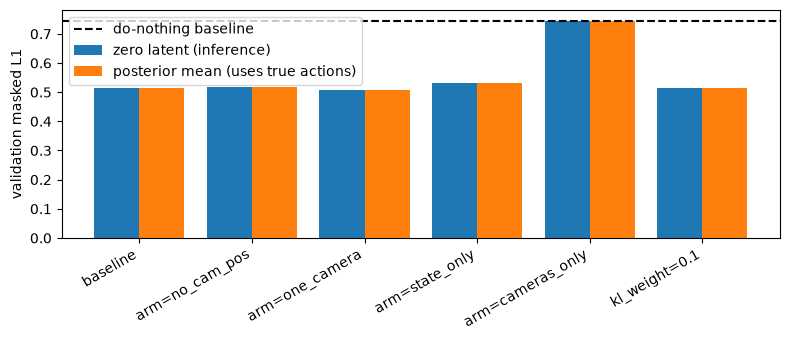

In [118]:
# Use your function: every trial against the do-nothing baseline
ok = [t for t in TRIALS if t["status"] == "ok"]
labels = [
    ", ".join(f"{k}={v}" for k, v in t["config"].items() if v != BASELINE[k]) or "baseline"
    for t in ok
]
fig, axis = plt.subplots(figsize=(8, 3.5))
axis.bar(
    [i - 0.2 for i in range(len(ok))],
    [t["val_l1_zero"] for t in ok],
    width=0.4,
    label="zero latent (inference)",
)
axis.bar(
    [i + 0.2 for i in range(len(ok))],
    [t["val_l1_posterior"] for t in ok],
    width=0.4,
    label="posterior mean (uses true actions)",
)
axis.axhline(do_nothing, color="k", linestyle="--", label="do-nothing baseline")
axis.set_xticks(range(len(ok)))
axis.set_xticklabels(labels, rotation=30, ha="right")
axis.set_ylabel("validation masked L1")
axis.legend()
plt.tight_layout()
plt.show()

**Explain (2–4 sentences, edit this cell).** Which arm was best and which worst? Is every arm better than the do-nothing baseline? Was `val_l1_posterior` much lower than `val_l1_zero`? What can you *not* conclude from 150 updates at 32×32 resolution?

*Optional extension:* repeat the best two arms with another `SEED_BATCH`. Keep both sets of rows.

## Optional: fine-tune the reference weights in your learner

This is an actual, bounded full-size training run. It starts from reference weights in the learner and runs 10 updates with your model, the training loss callback, and `train_loop`. It reports held-out L1 before and after training. It writes no checkpoint and does not measure simulator success. The code selects CUDA when available and otherwise uses CPU. Run the next cell to run it.

In [119]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
FINETUNE_STEPS, FINETUNE_BATCH, FINETUNE_LR = 10, 4, 1e-5  # the pinned recipe's learning rate

from lerobot.policies.act import ACTPolicy

checkpoint = DATA / "runs/act-bowl-plate-probe-200/checkpoint-000200"
if not (checkpoint / "model.safetensors").is_file():
    raise FileNotFoundError(f"Prepared ACT checkpoint missing: {checkpoint}")
config = ACTConfig.from_pretrained(checkpoint, local_files_only=True)
config.device = DEVICE
prepared = ACTPolicy.from_pretrained(checkpoint, config=config, strict=True, local_files_only=True)
learner_full = act_from_lerobot(prepared.model, hooks=YOUR_HOOKS).to(
    DEVICE
)  # reference weights in the learner
train = load_act_samples(
    CONFIGS, DATA, "bowl_plate", "train", count=24, chunk_size=config.chunk_size
)
valid = load_act_samples(
    CONFIGS, DATA, "bowl_plate", "validation", count=16, chunk_size=config.chunk_size
)
train = {
    key: value.to(DEVICE) if isinstance(value, torch.Tensor) else value
    for key, value in train.items()
}
valid = {
    key: value.to(DEVICE) if isinstance(value, torch.Tensor) else value
    for key, value in valid.items()
}


def held_out(model: torch.nn.Module) -> float:
    model.eval()
    with torch.no_grad():
        return masked_action_l1(model(valid)[0], valid["action"], valid["action_is_pad"]).item()


before_l1 = held_out(learner_full)
optimizer = torch.optim.AdamW(learner_full.parameters(), lr=FINETUNE_LR, weight_decay=1e-4)
draws = torch.Generator(device=DEVICE).manual_seed(1)
batches = []
for _ in range(FINETUNE_STEPS):
    pick = torch.randint(0, len(train["action"]), (FINETUNE_BATCH,), generator=draws, device=DEVICE)
    batches.append({key: value[pick] for key, value in train.items()})
history = train_loop(
    learner_full,
    batches,
    optimizer,
    partial(act_loss_fn, kl_weight=config.kl_weight),
    steps=FINETUNE_STEPS,
)
print("held-out L1 before (reference weights in the learner):", round(before_l1, 4))
print("held-out L1 after  (learner trained weights):         ", round(held_out(learner_full), 4))
print("training losses:", [round(h["loss"], 3) for h in history])

Loading weights from local directory
held-out L1 before (reference weights in the learner): 0.4742
held-out L1 after  (learner trained weights):          0.4836
training losses: [1.939, 1.41, 1.308, 1.169, 1.55, 1.445, 1.615, 1.082, 1.107, 1.534]


## What you built

- Five functions that make up ACT, wired into the real model through hooks and verified to give the pinned model's outputs for identical weights, on small random weights and on the prepared checkpoint at real size.
- A clear separation of *reference weights in the learner*, *learner trained weights* and *prepared policy results*.

**Next:** Lesson 9 fine-tunes the assembled ACT model. Lesson 10 starts diffusion policy with the forward noising process and training objective.